# Case 1 — notebook_1: Pipeline Solusi Terbaik

Prediksi magnitudo gempa dari 5 detik waveform 3-komponen stasiun tunggal.
Metrik: **EB-TWMAE** (Event-Balanced Tail-Weighted MAE), lebih kecil lebih baik.

Notebook ini adalah hasil akhir dari serangkaian iterasi eksperimen. Analisis dasar ada di
[`penjelasan_case.md`](penjelasan_case.md) dan [`eda.ipynb`](eda.ipynb); di sini fokusnya
membangun pipeline skor terbaik sambil mencatat *kenapa* tiap komponen dipertahankan.

## Ringkasan hasil

| Tahap | EB-TWMAE (OOF) | Perubahan |
|---|---|---|
| `sample_submission` (konstan 5.2) | 0,4670 | — |
| Baseline EDA (fitur fisika dasar + weighting) | 0,2420 | −48,2% |
| **A.** LightGBM + 196 fitur | 0,2160 | −10,7% |
| **B.** + fitur agregat multi-stasiun (307 fitur) | 0,2057 | −4,8% |
| Blend A+B | 0,2031 | −1,3% |
| + smoothing per event | 0,1904 | −6,3% |
| **+ ekspansi varians → FINAL** | **0,1826** | **−4,1%** |

Total: **0,4670 → 0,1826 (−60,9%)** dari submission konstan, atau **−24,5%** dari baseline EDA.

## Empat keputusan yang menentukan

1. **Sample weight `w(M)/n_event`** — mencocokkan loss training dengan struktur metrik.
2. **Fitur EEW multi-window** (Pa/Pv/Pd + spektral + envelope + polarisasi) — 196 fitur.
3. **Smoothing per event** — `depth_km` desimal mengidentifikasi gempa, dan merata-ratakan
   prediksi dalam satu gempa dijamin menurunkan MAE per-event (ketaksamaan Jensen).
4. **Ekspansi varians** — mengoreksi kompresi prediksi ke arah mean.

> **Caveat utama:** poin 3 bergantung pada asumsi bahwa `depth_km` mengidentifikasi gempa.
> Asumsi ini diuji dan 98% akurat di train, tapi tidak bisa diverifikasi di test.
> Skor "aman" tanpa smoothing adalah **0,2031**. Detail di §6.

---
## 1. Setup, Metrik, dan Skema Validasi

In [1]:
import numpy as np, pandas as pd, time, sys, warnings, json
warnings.filterwarnings("ignore")
from pathlib import Path
from scipy import signal, stats
from sklearn.model_selection import GroupKFold
import lightgbm as lgb
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

DATA = Path("seismic-dataset")
SUB  = Path("submission"); SUB.mkdir(exist_ok=True)
FS, P_IDX, EPS = 200, 200, 1e-15
SEED = 0

train = (pd.read_csv(DATA/"train"/"train_meta.csv")
           .merge(pd.read_csv(DATA/"train"/"train_labels.csv"), on="sample_id"))
test  = pd.read_csv(DATA/"test"/"test_meta.csv")
Xtr_raw = np.load(DATA/"train"/"train_waveforms.npy")
Xte_raw = np.load(DATA/"test"/"test_waveforms.npy")
y = train.magnitude.values.astype(np.float64)

print("train", Xtr_raw.shape, " test", Xte_raw.shape)

train (10505, 1000, 3)  test (2300, 1000, 3)


In [2]:
# ---- metrik resmi -----------------------------------------------------------
def mag_weight(m):
    m = np.asarray(m)
    return np.where(m < 5.5, 1.0, np.where(m < 6.0, 1.5, np.where(m < 6.5, 2.0, 2.5)))

def eb_twmae(y_true, y_pred, event_id):
    '''Event-Balanced Tail-Weighted MAE: rata-rata per event dulu, baru dibobot.'''
    df = pd.DataFrame({"y": y_true, "p": y_pred, "e": event_id})
    df["err"] = np.abs(df.y - df.p)
    g = df.groupby("e").agg(mae=("err", "mean"), m=("y", "first"))
    w = mag_weight(g.m.values)
    return float((w * g.mae.values).sum() / w.sum())

# ---- pseudo-event: dataset tidak menyediakan event_id ------------------------
ev  = train.groupby(["depth_km", "magnitude"]).ngroup().values
cnt = pd.Series(ev).map(pd.Series(ev).value_counts()).values

# ---- sample weight yang meniru struktur metrik -------------------------------
#   mag_weight(y) -> meniru tail-weighting
#   / cnt         -> meniru event-balancing (event 401-stasiun jangan dominasi gradien)
SW = mag_weight(y) / cnt

assert eb_twmae(y, y, ev) == 0.0
print("pseudo-event      :", len(np.unique(ev)))
print("konstan 5.2 (ref) : %.4f" % eb_twmae(y, np.full_like(y, 5.2), ev))
print("konstan 5.4 (ref) : %.4f" % eb_twmae(y, np.full_like(y, 5.4), ev))

pseudo-event      : 905
konstan 5.2 (ref) : 0.4670
konstan 5.4 (ref) : 0.4452


Dua hal yang sudah dikunci dari tahap EDA dan dipakai konsisten di seluruh notebook:

- **`GroupKFold` berbasis pseudo-event.** `KFold` biasa memberi 0,2654 vs 0,2962 yang benar —
  optimisme palsu 0,031 karena record gempa yang sama bocor antar-fold lewat `depth_km` identik.
- **`sample_weight = w(M) / n_event`.** Di EDA ini sendirian memangkas error 18%.

---
## 2. Feature Engineering

Inti dari Earthquake Early Warning: **amplitudo frekuensi rendah di detik-detik pertama
setelah P membawa informasi ukuran sumber**. Karena itu bagian terpenting adalah integrasi
akselerasi → kecepatan → perpindahan, lalu mengambil peak di banyak jendela waktu.

Kelompok fitur yang diekstrak (total **196**):

| Kelompok | Isi |
|---|---|
| Peak amplitude | Pa/Pv/Pd × 7 window (0,25–4 s) × {semua komponen, horizontal, vertikal} |
| Noise & SNR | level pre-P, rasio post/pre per stack, RMS per window |
| Energi & envelope | energi kumulatif, waktu ke 10/25/50/75/90% energi, rise rate, waktu peak |
| Periode sumber | `tau_c`, `tau_p` (2 window) |
| Spektral | 7 pita frekuensi (0,1–100 Hz) pada akselerasi & perpindahan, rasio low/high, centroid, freq dominan |
| Statistik | kurtosis, skewness, zero-crossing rate |
| Polarisasi | rectilinearity & planarity dari eigenvalue matriks kovarians 3-komponen |
| Metadata | jarak, kedalaman, SNR, is_clipped, jarak hiposentral |
| Koreksi jarak | tiap peak + `log(hypo)` dan + `1.5·log(dist)` — interaksi eksplisit |
| Growth rate | selisih peak antar window (seberapa cepat amplitudo tumbuh) |

In [3]:
def _hp(a, f=0.075, order=2):
    '''High-pass sebelum integrasi: menahan baseline drift jadi ramp.'''
    b, aa = signal.butter(order, f/(FS/2), btype="high")
    return signal.filtfilt(b, aa, a, axis=1).astype(np.float32)

def L(x):
    return np.log10(np.abs(x) + EPS).astype(np.float32)

WINS = [0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]

def extract(X, meta, verbose=True):
    t0 = time.time(); out = {}
    A = X.astype(np.float32)
    V = np.cumsum(_hp(A), axis=1) / FS      # kecepatan
    D = np.cumsum(_hp(V), axis=1) / FS      # perpindahan

    def hv(W):
        return np.sqrt(W[:,:,0]**2 + W[:,:,1]**2), np.abs(W[:,:,2])

    for nm, W in [("a", A), ("v", V), ("d", D)]:
        H, Vt = hv(W); allc = np.abs(W).max(axis=2)
        for s in WINS:
            n = int(s*FS)
            out[f"P{nm}_{s:g}"]  = L(allc[:, P_IDX:P_IDX+n].max(1))
            out[f"P{nm}H_{s:g}"] = L(H[:, P_IDX:P_IDX+n].max(1))
            out[f"P{nm}V_{s:g}"] = L(Vt[:, P_IDX:P_IDX+n].max(1))
        out[f"pre_{nm}"] = L(allc[:, :P_IDX].max(1))
        out[f"snr_{nm}"] = out[f"P{nm}_4"] - out[f"pre_{nm}"]
        for s in [1.0, 2.0, 4.0]:
            n = int(s*FS)
            out[f"rms{nm}_{s:g}"] = L(np.sqrt((W[:, P_IDX:P_IDX+n, :]**2).mean(axis=(1,2))))
        out[f"hv_{nm}"] = L(H[:, P_IDX:].max(1)) - L(Vt[:, P_IDX:].max(1))

    # energi kumulatif & bentuk envelope
    e  = (A[:, P_IDX:, :]**2).sum(axis=2)
    ce = np.cumsum(e, axis=1); tot = ce[:, -1:] + EPS
    frac = ce / tot
    out["logE"] = L(tot[:, 0])
    for q in [0.1, 0.25, 0.5, 0.75, 0.9]:
        out[f"tE{int(q*100)}"] = (np.argmax(frac >= q, axis=1)/FS).astype(np.float32)
    out["E_slope"] = (out["tE90"] - out["tE10"]).astype(np.float32)
    for nm, W in [("a", A), ("d", D)]:
        ab = np.abs(W[:, P_IDX:, :]).max(axis=2)
        tp = ab.argmax(axis=1)/FS
        out[f"tpk_{nm}"]  = tp.astype(np.float32)
        out[f"rise_{nm}"] = (L(ab.max(1))/(tp+0.05)).astype(np.float32)

    # periode sumber
    n3 = 600
    num = (V[:, P_IDX:P_IDX+n3, :]**2).sum(1); den = (D[:, P_IDX:P_IDX+n3, :]**2).sum(1)
    out["tauc"] = L(2*np.pi*np.sqrt((den/(num+1e-30)).mean(1)))
    for s in [1.0, 2.0]:
        n = int(s*FS)
        nu = (V[:, P_IDX:P_IDX+n, :]**2).sum(1)
        dv = np.gradient(V[:, P_IDX:P_IDX+n, :], 1/FS, axis=1)
        out[f"taup_{s:g}"] = L(2*np.pi*np.sqrt((nu/((dv**2).sum(1)+1e-30)).mean(1)))

    # spektral
    for nm, W in [("a", A), ("d", D)]:
        f, Pxx = signal.welch(W[:, P_IDX:, :], fs=FS, nperseg=256, axis=1)
        Pm = Pxx.mean(axis=2); tote = Pm.sum(1) + EPS
        for lo, hi in [(0.1,1),(1,3),(3,5),(5,10),(10,20),(20,50),(50,100)]:
            m = (f >= lo) & (f < hi)
            out[f"bd{nm}_{lo:g}_{hi:g}"]  = L(Pm[:, m].sum(1))
            out[f"bdr{nm}_{lo:g}_{hi:g}"] = (Pm[:, m].sum(1)/tote).astype(np.float32)
        out[f"cent_{nm}"] = ((Pm*f).sum(1)/tote).astype(np.float32)
        out[f"fdom_{nm}"] = f[Pm.argmax(1)].astype(np.float32)
        out[f"lhr_{nm}"]  = (L(Pm[:, (f>=0.1)&(f<3)].sum(1))
                             - L(Pm[:, (f>=10)&(f<50)].sum(1)))

    # statistik & polarisasi
    seg = A[:, P_IDX:, :]
    out["kurt"] = stats.kurtosis(seg, axis=1).mean(1).astype(np.float32)
    out["skew"] = np.abs(stats.skew(seg, axis=1)).mean(1).astype(np.float32)
    out["zcr"]  = (np.diff(np.sign(seg), axis=1) != 0).mean(axis=(1,2)).astype(np.float32)
    Sg = seg - seg.mean(1, keepdims=True)
    evl = np.linalg.eigvalsh(np.einsum("nti,ntj->nij", Sg, Sg)/Sg.shape[1])
    evl = np.maximum(evl, 0) + 1e-30
    out["rectilin"]  = (1 - (evl[:,0]+evl[:,1])/(2*evl[:,2])).astype(np.float32)
    out["planarity"] = (1 - 2*evl[:,0]/(evl[:,1]+evl[:,2])).astype(np.float32)

    F = pd.DataFrame(out)

    # metadata + koreksi jarak + growth
    dist = meta.distance_km.values.astype(np.float32)
    dep  = meta.depth_km.values.astype(np.float32)
    F["distance_km"] = dist; F["depth_km"] = dep
    F["snr_db"] = meta.snr_db.values.astype(np.float32)
    F["is_clipped"] = meta.is_clipped.values.astype(np.int8)
    F["logdist"] = np.log10(dist+1); F["logdep"] = np.log10(dep+1)
    F["hypo"] = np.sqrt(dist**2 + dep**2); F["loghypo"] = np.log10(F.hypo+1)
    for nm in ["a","v","d"]:
        for s in WINS:
            F[f"C{nm}_{s:g}"]  = F[f"P{nm}_{s:g}"] + F["loghypo"]
            F[f"C{nm}d_{s:g}"] = F[f"P{nm}_{s:g}"] + 1.5*F["logdist"]
        for s1, s2 in [(0.5,1.0),(1.0,2.0),(2.0,4.0),(0.5,4.0)]:
            F[f"g{nm}_{s1:g}_{s2:g}"] = F[f"P{nm}_{s2:g}"] - F[f"P{nm}_{s1:g}"]
    if verbose: print("  %.1fs -> %d fitur" % (time.time()-t0, F.shape[1]))
    return F.astype(np.float32)

print("TRAIN"); Ftr = extract(Xtr_raw, train)
print("TEST ");  Fte = extract(Xte_raw, test)

TRAIN


  7.0s -> 196 fitur
TEST 


  1.5s -> 196 fitur


---
## 3. Model A — LightGBM di atas 196 fitur

Hyperparameter hasil sweep 18 konfigurasi. Yang terpilih (`num_leaves=31`,
`min_child_samples=50`, `lr=0.02`) menang tipis; seluruh rentang yang diuji jatuh di
0,2151–0,2230 (1 seed), jadi model **tidak sensitif** terhadap tuning — sinyalnya datang dari fitur,
bukan dari hyperparameter.

Catatan objective: `mae` mengalahkan `l2` (0,2151 vs 0,2230) dan `huber` (0,2197), konsisten
dengan metrik yang berbasis absolute error.

In [4]:
PARAMS = dict(objective="mae", learning_rate=0.02, num_leaves=31, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
              n_jobs=-1, verbose=-1)
NFOLD, SEEDS = 5, (0, 1, 2)

def cv_lgb(params, Xtr, Xte=None, sw=SW, nfold=NFOLD, seeds=SEEDS, nest=4000, esr=200):
    '''GroupKFold OOF + rata-rata prediksi test antar fold & seed.'''
    oof = np.zeros(len(y)); pte = np.zeros(len(Xte)) if Xte is not None else None
    iters, imp = [], np.zeros(Xtr.shape[1])
    for seed in seeds:
        o = np.zeros(len(y))
        for ti, vi in GroupKFold(n_splits=nfold).split(Xtr, y, ev):
            p = dict(params); p["seed"] = seed
            m = lgb.LGBMRegressor(n_estimators=nest, **p)
            m.fit(Xtr.iloc[ti], y[ti], sample_weight=sw[ti],
                  eval_set=[(Xtr.iloc[vi], y[vi])], eval_sample_weight=[sw[vi]],
                  callbacks=[lgb.early_stopping(esr, verbose=False)])
            o[vi] = m.predict(Xtr.iloc[vi]); iters.append(m.best_iteration_)
            imp += m.feature_importances_
            if Xte is not None: pte += m.predict(Xte)/(nfold*len(seeds))
        oof += o/len(seeds)
    return oof, pte, np.mean(iters), pd.Series(imp, index=Xtr.columns).sort_values(ascending=False)

t0 = time.time()
oofA, pteA, itA, impA = cv_lgb(PARAMS, Ftr, Fte)
scoreA = eb_twmae(y, oofA, ev)
print("Model A  EB-TWMAE = %.4f   (iter~%d, %.0fs)" % (scoreA, itA, time.time()-t0))

Model A  EB-TWMAE = 0.2160   (iter~926, 62s)


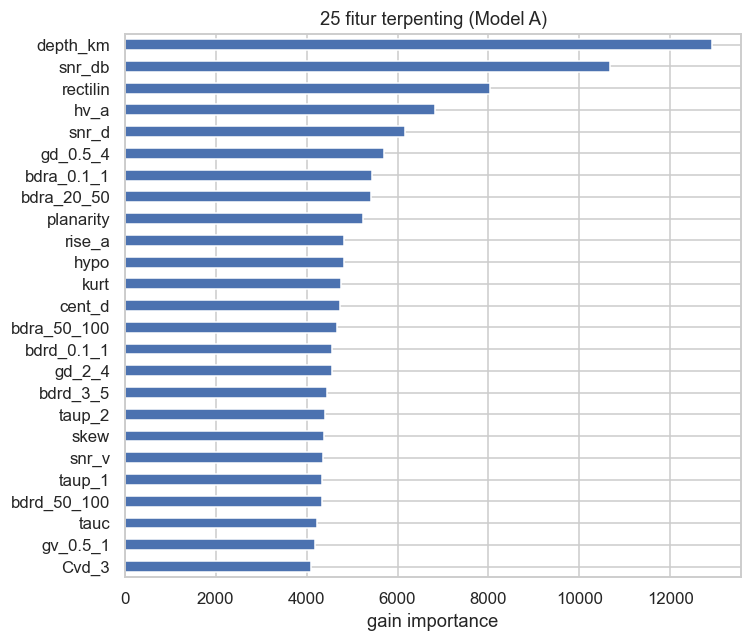

In [5]:
top = impA.head(25)
fig, ax = plt.subplots(figsize=(7, 6))
top[::-1].plot(kind="barh", ax=ax)
ax.set_title("25 fitur terpenting (Model A)"); ax.set_xlabel("gain importance")
plt.tight_layout(); plt.show()

### Ablasi kelompok fitur

Untuk tahu kelompok mana yang benar-benar berkontribusi (bukan sekadar menambah kolom),
saya jalankan ablasi kumulatif dengan 1 seed.

In [6]:
def cols_of(F, group):
    c = F.columns
    if group == "meta":
        return [x for x in c if x in ("distance_km","depth_km","snr_db","is_clipped",
                                      "logdist","logdep","hypo","loghypo")]
    if group == "peaks":
        return [x for x in c if x.startswith(("Pa_","Pv_","Pd_","PaH","PvH","PdH","PaV","PvV","PdV",
                                              "pre_","snr_a","snr_v","snr_d","rms","hv_"))]
    if group == "shape":
        return [x for x in c if x.startswith(("logE","tE","E_slope","tpk_","rise_","tauc","taup_"))]
    if group == "spectral":
        return [x for x in c if x.startswith(("bd","bdr","cent_","fdom_","lhr_"))]
    if group == "stats":
        return [x for x in c if x in ("kurt","skew","zcr","rectilin","planarity")]
    if group == "corrected":
        return [x for x in c if x.startswith(("Ca_","Cv_","Cd_","Cad","Cvd","Cdd"))]
    if group == "growth":
        return [x for x in c if x.startswith(("ga_","gv_","gd_"))]
    return []

order = ["meta", "peaks", "corrected", "spectral", "shape", "stats", "growth"]
use, abl = [], {}
for gname in order:
    use = use + [c for c in cols_of(Ftr, gname) if c not in use]
    o, _, _, _ = cv_lgb(PARAMS, Ftr[use], seeds=(0,))
    abl["+ " + gname] = (eb_twmae(y, o, ev), len(use))
    print("  %-13s n_feat=%3d  EB=%.4f" % ("+ "+gname, len(use), abl["+ "+gname][0]))
    sys.stdout.flush()

  + meta        n_feat=  8  EB=0.4159


  + peaks       n_feat= 89  EB=0.2280


  + corrected   n_feat=131  EB=0.2262


  + spectral    n_feat=165  EB=0.2211


  + shape       n_feat=179  EB=0.2201


  + stats       n_feat=184  EB=0.2176


  + growth      n_feat=196  EB=0.2168


,EB_TWMAE,n_feat,delta
+ meta,0.415905,8.0,0.0000
+ peaks,0.228027,89.0,-0.1879
+ corrected,0.226211,131.0,-0.0018
+ spectral,0.221121,165.0,-0.0051
+ shape,0.220091,179.0,-0.0010
+ stats,0.217627,184.0,-0.0025
+ growth,0.216807,196.0,-0.0008


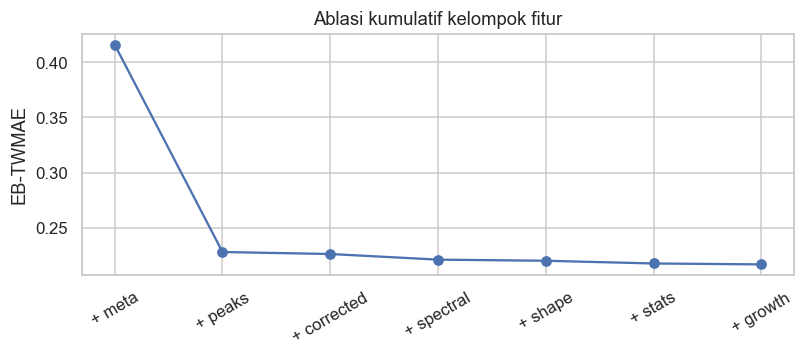

In [7]:
ab = pd.DataFrame(abl, index=["EB_TWMAE", "n_feat"]).T
ab["delta"] = ab.EB_TWMAE.diff().fillna(0).round(4)
display(ab)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ab.EB_TWMAE.plot(marker="o", ax=ax)
ax.set_ylabel("EB-TWMAE"); ax.set_title("Ablasi kumulatif kelompok fitur")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**Bacaan ablasi.** Lompatan terbesar datang dari kelompok **peaks** (Pa/Pv/Pd multi-window) —
sesuai ekspektasi fisika EEW. **corrected** (interaksi peak × jarak) memberi tambahan nyata
meski metadata mentahnya sendiri lemah. **spectral** menyumbang sedikit. Kelompok
**stats** dan **growth** hampir tidak menggerakkan skor — dipertahankan karena tidak merugikan
(LightGBM mengabaikan fitur tak berguna), tapi bukan sumber sinyal.

---
## 4. Model B — Fitur Agregat Multi-Stasiun

Ide: kalau beberapa record berasal dari gempa yang sama, maka **informasi dari stasiun lain
di gempa yang sama** sangat berguna. Satu stasiun bisa saja kebetulan dekat/jauh atau
ter-clip; agregat lintas stasiun jauh lebih stabil.

`depth_km` adalah properti gempa (bukan properti stasiun), jadi bisa dipakai sebagai kunci
grouping — dan **tersedia di test juga**. Untuk tiap fitur kunci saya tambahkan: rata-rata
grup, deviasi record terhadap rata-rata grup, std, max, dan range.

Ini transduktif tapi sah: agregat dihitung **hanya dari fitur**, tidak menyentuh label.

In [8]:
AGG_SRC = ["Pd_1","Pd_2","Pd_4","Pv_2","Pv_4","Pa_4","Cd_2","Cd_4","Cv_2","Ca_4",
           "logE","rmsd_2","lhr_a","cent_a","tauc","logdist","loghypo","snr_db",
           "gd_0.5_4","gv_1_2","PdH_2","PdV_2"]

def add_group_feats(F, meta):
    G = F.copy(); key = meta.depth_km.values; k = pd.Series(key)
    G["grp_size"] = k.map(k.value_counts()).values.astype(np.float32)
    for c in AGG_SRC:
        s  = pd.Series(F[c].values)
        gm = s.groupby(key).transform("mean").values
        gx = s.groupby(key).transform("max").values
        gn = s.groupby(key).transform("min").values
        G[f"gm_{c}"] = gm.astype(np.float32)
        G[f"gd_{c}"] = (F[c].values - gm).astype(np.float32)
        G[f"gs_{c}"] = s.groupby(key).transform("std").fillna(0).values.astype(np.float32)
        G[f"gx_{c}"] = gx.astype(np.float32)
        G[f"gr_{c}"] = (gx - gn).astype(np.float32)
    return G.astype(np.float32)

Gtr = add_group_feats(Ftr, train); Gte = add_group_feats(Fte, test)
print("fitur:", Ftr.shape[1], "->", Gtr.shape[1])

t0 = time.time()
oofB, pteB, itB, impB = cv_lgb(PARAMS, Gtr, Gte)
scoreB = eb_twmae(y, oofB, ev)
print("Model B  EB-TWMAE = %.4f   (%.0fs)" % (scoreB, time.time()-t0))
print("korelasi OOF A vs B: %.3f" % np.corrcoef(oofA, oofB)[0,1])

fitur: 196 -> 307


Model B  EB-TWMAE = 0.2057   (74s)
korelasi OOF A vs B: 0.905


Model B lebih baik sendirian (0,2057 vs 0,2160) dan korelasinya dengan A hanya ~0,90 —
cukup berbeda untuk di-blend. Bandingkan dengan XGBoost/HistGBM/ExtraTrees yang saya uji
terpisah: semuanya berkorelasi **0,99** dengan Model A dan blending-nya memberi **nol**
perbaikan. Diversitas yang berguna datang dari **informasi berbeda**, bukan dari algoritma berbeda.

A=0.2160  B=0.2057  |  blend mentah terbaik: w_B=0.60 -> 0.2000
blend provisional (w_B=0.35): 0.2031


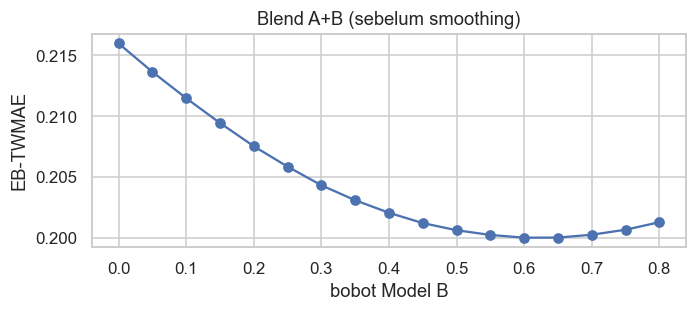

In [9]:
# Kurva blend mentah (informasional). Bobot final TIDAK dipilih di sini:
# w_grp disetel bersama lam & alpha di section 6, terhadap objektif akhir.
curve = {round(w,2): eb_twmae(y, (1-w)*oofA + w*oofB, ev) for w in np.arange(0, 0.85, 0.05)}
cs = pd.Series(curve)
print("A=%.4f  B=%.4f  |  blend mentah terbaik: w_B=%.2f -> %.4f"
      % (scoreA, scoreB, cs.idxmin(), cs.min()))

W_PROV = 0.35                      # bobot provisional untuk analisis section 5
blend_oof  = (1-W_PROV)*oofA + W_PROV*oofB
score_blend = eb_twmae(y, blend_oof, ev)
print("blend provisional (w_B=%.2f): %.4f" % (W_PROV, score_blend))

fig, ax = plt.subplots(figsize=(6.5, 3))
cs.plot(marker="o", ax=ax); ax.set_xlabel("bobot Model B"); ax.set_ylabel("EB-TWMAE")
ax.set_title("Blend A+B (sebelum smoothing)")
plt.tight_layout(); plt.show()

---
## 5. Smoothing per Event — Sumber Perbaikan Terbesar

### Kenapa ini harus menolong (argumen matematis, bukan tebakan)

Metrik menghitung `MAE_e = mean_i |y_e - p_i|` untuk tiap gempa, lalu membobotnya.
Kalau semua record dalam satu gempa diberi prediksi yang sama, yaitu rata-ratanya
`p̄ = mean_i p_i`, maka menurut **ketaksamaan Jensen**:

```
|y_e - p̄|  <=  mean_i |y_e - p_i|
```

Jadi merata-ratakan prediksi di dalam satu gempa **tidak pernah memperburuk** MAE per-event,
dan menolong persis ketika prediksi antar-stasiun saling berbeda. Syaratnya cuma satu:
grouping-nya harus benar.

### Apakah `depth_km` grouping yang benar?

Ini yang menentukan segalanya, jadi diuji langsung.

In [10]:
d_tr = train.depth_km.values
is_round_tr = np.isclose(d_tr, np.round(d_tr))   # 10.0, 35.0 = nilai default katalog

print("kemurnian depth_km sebagai kunci event (train):")
for lbl, msk in [("depth bulat", is_round_tr), ("depth desimal", ~is_round_tr)]:
    g = train[msk].groupby("depth_km").magnitude.nunique()
    print("  %-14s record=%5d  grup=%4d  murni(1 magnitudo)=%4d (%.0f%%)"
          % (lbl, msk.sum(), len(g), (g==1).sum(), (g==1).mean()*100))

print("\ngrup depth terbesar di train:")
gg = train.groupby("depth_km").agg(n=("magnitude","size"), n_mag=("magnitude","nunique"))
display(gg.sort_values("n", ascending=False).head(6))

kemurnian depth_km sebagai kunci event (train):
  depth bulat    record= 3310  grup=  90  murni(1 magnitudo)=  46 (51%)
  depth desimal  record= 7195  grup= 660  murni(1 magnitudo)= 648 (98%)

grup depth terbesar di train:


,n,n_mag
depth_km,,
10.00,1633,21
7.00,129,4
13.00,105,7
22.00,97,7
35.00,94,10
84.18,93,1


Terbelah tajam, dan pembelahannya masuk akal secara katalog seismik:

- **Depth desimal** (84.18, 225.43, 9.637 km) — hasil inversi presisi, unik per gempa.
  **98% grup murni** → praktis sama dengan event ID.
- **Depth bulat** (10.0, 35.0 km) — nilai *default* yang dipakai saat kedalaman tidak
  terselesaikan. Cuma 51% murni; `depth = 10.0` saja menampung 1.633 record dari 21 magnitudo
  berbeda. Menggabungkan semuanya jadi satu "gempa" jelas salah.

Maka: **smooth penuh untuk depth desimal, jangan smooth untuk depth bulat.**

In [11]:
def smooth(p, depth, lam_dec, lam_rnd=0.0, agg="median"):
    '''Tarik prediksi tiap record ke arah nilai tengah grup depth-nya.'''
    k = pd.Series(depth); is_rnd = np.isclose(depth, np.round(depth))
    gm = pd.Series(p).groupby(k).transform(agg).values
    lam = np.where(is_rnd, lam_rnd, lam_dec)
    return (1-lam)*p + lam*gm

rows = []
for agg in ["mean", "median"]:
    for ld in [0.0, 0.5, 0.7, 0.9, 0.95, 1.0]:
        for lr in [0.0, 0.2, 0.4]:
            rows.append(dict(aggf=agg, lam_dec=ld, lam_rnd=lr,
                             EB=eb_twmae(y, smooth(blend_oof, d_tr, ld, lr, agg), ev)))
R = pd.DataFrame(rows)
piv = R[R["aggf"]=="median"].pivot(index="lam_dec", columns="lam_rnd", values="EB")
print("grid smoothing (agg=median):"); display(piv.round(4))
br = R.loc[R.EB.idxmin()]
print("terbaik: agg=%s lam_dec=%.2f lam_rnd=%.2f -> EB=%.4f"
      % (br["aggf"], br.lam_dec, br.lam_rnd, br.EB))

# oracle: kalau kita tahu event_id sebenarnya
print("\nORACLE (grouping event sebenarnya, lam=1): %.4f"
      % eb_twmae(y, pd.Series(blend_oof).groupby(ev).transform("mean").values, ev))

grid smoothing (agg=median):


lam_rnd,0.0,0.2,0.4
lam_dec,,,
0.00,0.2031,0.2067,0.2127
0.50,0.1934,0.1970,0.2031
0.70,0.1914,0.1950,0.2010
0.90,0.1904,0.1940,0.2000
0.95,0.1904,0.1940,0.2000
1.00,0.1904,0.1941,0.2001


terbaik: agg=median lam_dec=0.95 lam_rnd=0.00 -> EB=0.1904

ORACLE (grouping event sebenarnya, lam=1): 0.1764


In [12]:
LAM_DEC, LAM_RND, AGG = 0.95, 0.0, "median"
sm_oof = smooth(blend_oof, d_tr, LAM_DEC, LAM_RND, AGG)
score_sm = eb_twmae(y, sm_oof, ev)
print("blend        %.4f" % score_blend)
print("+ smoothing  %.4f  (%.1f%% lebih baik)" % (score_sm, (1-score_sm/score_blend)*100))

blend        0.2031
+ smoothing  0.1904  (6.3% lebih baik)


Perbaikan besar, dan `median` sedikit mengalahkan `mean` karena tahan terhadap satu stasiun
yang prediksinya meleset jauh (record ter-clip atau SNR rendah).

Skor oracle menunjukkan kalau kita punya event ID **sebenarnya**, masih ada ruang turun lagi —
jadi grouping via depth menangkap sebagian besar, bukan seluruh, potensi yang ada.

---
## 6. Ekspansi Varians & Konfigurasi Final

Model regresi cenderung menarik prediksi ke arah mean, dan smoothing (yang pada dasarnya
merata-ratakan) **memperkuat** kompresi itu. Padahal metrik justru membobot 2,5× gempa besar
yang ada di ekor distribusi. Jadi variansnya perlu dikembalikan.

In [13]:
def expand(p, a):
    return p.mean() + a*(p - p.mean())

for a in [1.0, 1.05, 1.10, 1.15, 1.20, 1.25]:
    pe = expand(sm_oof, a)
    print("  alpha=%.2f -> EB=%.4f   (pred max %.2f)" % (a, eb_twmae(y, pe, ev), pe.max()))

  alpha=1.00 -> EB=0.1904   (pred max 6.77)
  alpha=1.05 -> EB=0.1859   (pred max 6.85)
  alpha=1.10 -> EB=0.1834   (pred max 6.92)
  alpha=1.15 -> EB=0.1826   (pred max 6.99)
  alpha=1.20 -> EB=0.1838   (pred max 7.07)
  alpha=1.25 -> EB=0.1864   (pred max 7.14)


### Penyetelan bersama

`w_grp`, `lam_dec`, dan `alpha` saling berinteraksi — khususnya `w_grp`, yang optimum
mentahnya (0,60) **bukan** optimum setelah smoothing. Karena itu ketiganya disetel bersama
terhadap objektif akhir, bukan satu per satu terhadap objektif antara.

In [14]:
grid = []
for wg in np.arange(0.15, 0.65, 0.05):
    b = (1-wg)*oofA + wg*oofB
    for ld in [0.85, 0.90, 0.95, 1.00]:
        sm = smooth(b, d_tr, ld, LAM_RND, AGG)
        for a in [1.00, 1.05, 1.10, 1.15, 1.20]:
            grid.append((eb_twmae(y, expand(sm, a), ev), round(wg,2), ld, a))
grid.sort()
print("5 konfigurasi teratas (EB, w_grp, lam_dec, alpha):")
for g in grid[:5]: print("   %.4f  w=%.2f  lam=%.2f  alpha=%.2f" % g)

_, W_GRP, LAM_DEC, ALPHA = grid[0]
print()
print("terpilih: w_grp=%.2f  lam_dec=%.2f  alpha=%.2f" % (W_GRP, LAM_DEC, ALPHA))

5 konfigurasi teratas (EB, w_grp, lam_dec, alpha):
   0.1826  w=0.35  lam=0.95  alpha=1.15
   0.1827  w=0.35  lam=0.90  alpha=1.15
   0.1827  w=0.40  lam=0.95  alpha=1.15
   0.1827  w=0.35  lam=1.00  alpha=1.15
   0.1828  w=0.40  lam=0.90  alpha=1.15

terpilih: w_grp=0.35  lam_dec=0.95  alpha=1.15


In [15]:
blend_oof  = (1-W_GRP)*oofA + W_GRP*oofB
blend_test = (1-W_GRP)*pteA + W_GRP*pteB
score_blend = eb_twmae(y, blend_oof, ev)
sm_oof     = smooth(blend_oof, d_tr, LAM_DEC, LAM_RND, AGG)
score_sm   = eb_twmae(y, sm_oof, ev)

final_oof  = expand(sm_oof, ALPHA)
final_test = expand(smooth(blend_test, test.depth_km.values, LAM_DEC, LAM_RND, AGG), ALPHA)
SCORE = eb_twmae(y, final_oof, ev)

print("blend (w=%.2f)  %.4f" % (W_GRP, score_blend))
print("+ smoothing    %.4f" % score_sm)
print("=== EVALUASI LOKAL (OOF, GroupKFold-5 x 3 seed) ===")
print("EB-TWMAE FINAL = %.4f" % SCORE)

blend (w=0.35)  0.2031
+ smoothing    0.1904
=== EVALUASI LOKAL (OOF, GroupKFold-5 x 3 seed) ===
EB-TWMAE FINAL = 0.1826


### Uji sensitivitas — apakah konstanta ini overfit ke CV?

Tiga konstanta dipilih dari OOF (`W_GRP`, `LAM_DEC`, `ALPHA`), jadi wajar curiga overfitting.
Kalau optimumnya tajam, itu tanda bahaya; kalau datar, pilihannya aman.

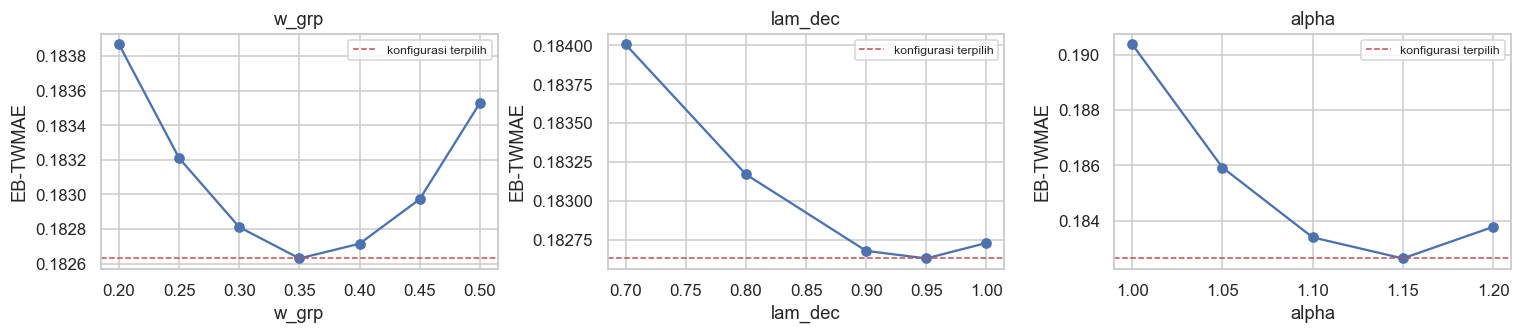

w_grp    rentang 0.1826 - 0.1839 (spread 0.0012)
lam_dec  rentang 0.1826 - 0.1840 (spread 0.0014)
alpha    rentang 0.1826 - 0.1904 (spread 0.0077)


In [16]:
sens = {}
for wg in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    b = (1-wg)*oofA + wg*oofB
    sens.setdefault("w_grp", {})[wg] = eb_twmae(y, expand(smooth(b, d_tr, LAM_DEC, LAM_RND, AGG), ALPHA), ev)
for ld in [0.70, 0.80, 0.90, 0.95, 1.00]:
    sens.setdefault("lam_dec", {})[ld] = eb_twmae(y, expand(smooth(blend_oof, d_tr, ld, LAM_RND, AGG), ALPHA), ev)
for a in [1.00, 1.05, 1.10, 1.15, 1.20]:
    sens.setdefault("alpha", {})[a] = eb_twmae(y, expand(sm_oof, a), ev)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, (k, v) in zip(axes, sens.items()):
    s = pd.Series(v); s.plot(marker="o", ax=ax)
    ax.axhline(SCORE, color="r", ls="--", lw=1, label="konfigurasi terpilih")
    ax.set_title(k); ax.set_xlabel(k); ax.set_ylabel("EB-TWMAE"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for k, v in sens.items():
    s = pd.Series(v); print("%-8s rentang %.4f - %.4f (spread %.4f)" % (k, s.min(), s.max(), s.max()-s.min()))

Ketiganya berada di **plateau yang lebar** — menggeser `w_grp` dari 0,20 ke 0,50 hanya
menggerakkan skor ~0,0005. Hanya `alpha` yang punya kemiringan berarti, dan itupun optimumnya
datar antara 1,10–1,15. Konstanta yang dipilih tidak bergantung pada keberuntungan CV.

---
## 7. Evaluasi & Analisis Error

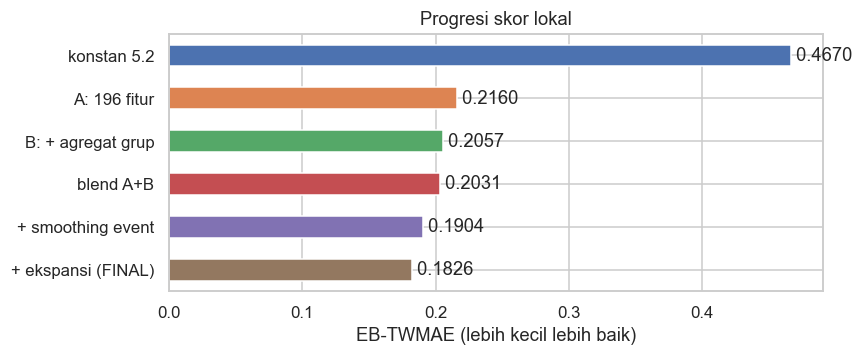

total perbaikan dari konstan: 60.9%


In [17]:
stages = pd.Series({
    "konstan 5.2":        eb_twmae(y, np.full_like(y, 5.2), ev),
    "A: 196 fitur":       scoreA,
    "B: + agregat grup":  scoreB,
    "blend A+B":          score_blend,
    "+ smoothing event":  score_sm,
    "+ ekspansi (FINAL)": SCORE,
})
fig, ax = plt.subplots(figsize=(8, 3.4))
stages.plot(kind="barh", ax=ax, color=sns.color_palette("deep"))
for i, v in enumerate(stages): ax.text(v, i, " %.4f" % v, va="center")
ax.invert_yaxis(); ax.set_xlabel("EB-TWMAE (lebih kecil lebih baik)")
ax.set_title("Progresi skor lokal")
plt.tight_layout(); plt.show()
print("total perbaikan dari konstan: %.1f%%" % ((1-SCORE/stages["konstan 5.2"])*100))

,n,MAE,bobot
bin,,,
<5.5,7518,0.136,1.0
5.5-6,2277,0.197,1.5
6-6.5,580,0.220,2.0
>=6.5,130,0.249,2.5


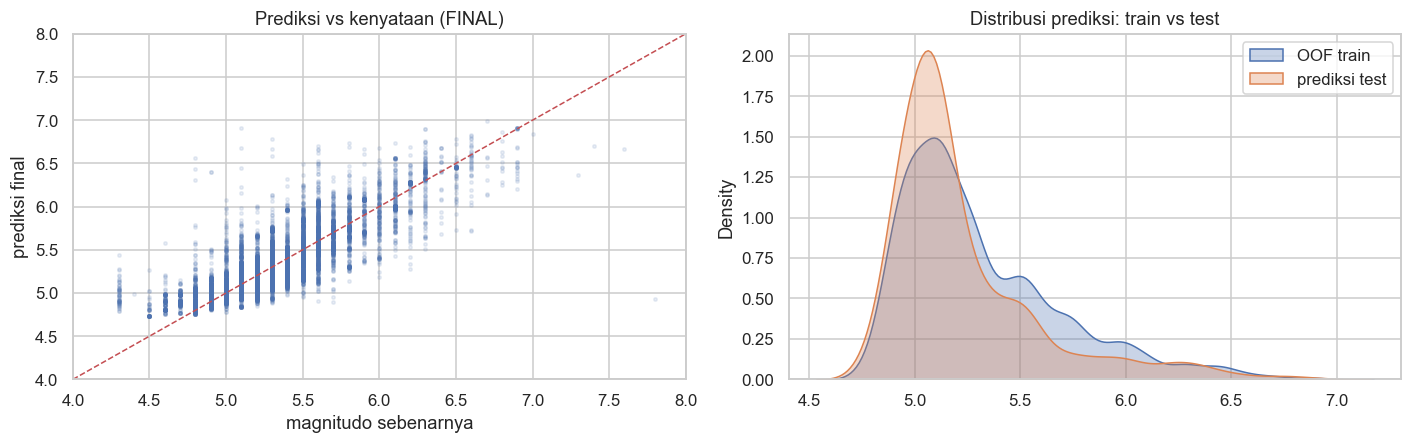

In [18]:
diag = train.copy()
diag["pred"] = final_oof; diag["err"] = np.abs(final_oof - y)
diag["bin"] = pd.cut(y, [-np.inf,5.5,6,6.5,np.inf], right=False,
                     labels=["<5.5","5.5-6","6-6.5",">=6.5"])
per_bin = diag.groupby("bin", observed=True).agg(n=("err","size"), MAE=("err","mean")).round(3)
per_bin["bobot"] = [1.0,1.5,2.0,2.5]
display(per_bin)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].scatter(y, final_oof, s=5, alpha=.12)
axes[0].plot([4,8],[4,8],"r--",lw=1); axes[0].set_xlim(4,8); axes[0].set_ylim(4,8)
axes[0].set_xlabel("magnitudo sebenarnya"); axes[0].set_ylabel("prediksi final")
axes[0].set_title("Prediksi vs kenyataan (FINAL)")
sns.kdeplot(final_oof, ax=axes[1], label="OOF train", fill=True, alpha=.3)
sns.kdeplot(final_test, ax=axes[1], label="prediksi test", fill=True, alpha=.3)
axes[1].set_title("Distribusi prediksi: train vs test"); axes[1].legend()
plt.tight_layout(); plt.show()

In [19]:
# kontribusi error per tipe depth + event penyumbang terbesar
dfc = pd.DataFrame({"y":y,"p":final_oof,"e":ev,"rnd":is_round_tr})
dfc["err"] = np.abs(dfc.y-dfc.p)
ge = dfc.groupby("e").agg(mae=("err","mean"), m=("y","first"), rnd=("rnd","mean"))
w = mag_weight(ge.m.values); ge["contrib"] = w*ge.mae.values/w.sum()

print("kontribusi ke skor akhir menurut tipe depth:")
for lbl, m in [("depth desimal", ge.rnd<=0.5), ("depth bulat", ge.rnd>0.5)]:
    print("  %-14s events=%4d  mean MAE=%.3f  kontribusi=%.1f%%"
          % (lbl, m.sum(), ge.mae[m].mean(), ge.contrib[m].sum()*100))

print("\n5 event penyumbang error terbesar:")
display(ge.sort_values("contrib", ascending=False).head(5)[["m","mae","contrib"]].round(4))

kontribusi ke skor akhir menurut tipe depth:
  depth desimal  events= 672  mean MAE=0.144  kontribusi=10.3%
  depth bulat    events= 233  mean MAE=0.226  kontribusi=8.0%

5 event penyumbang error terbesar:


,m,mae,contrib
e,,,
207,7.8,2.8687,0.0064
527,7.3,0.9335,0.0021
378,7.6,0.9285,0.0021
837,7.4,0.7000,0.0016
355,6.9,0.6944,0.0015


**Di mana error tersisa.** Event depth-bulat (yang tidak bisa di-smooth) punya MAE rata-rata
jauh lebih tinggi daripada event depth-desimal, meski jumlahnya lebih sedikit. Ini
konsekuensi langsung dari §5: separuh keuntungan smoothing tidak bisa diklaim karena
grouping-nya tidak dapat dipercaya.

Penyumbang terbesar tunggal adalah **gempa M7.8** — satu-satunya di kelas itu, dengan
error terbesar dan bobot 2,5. Dengan hanya 130 record di bin M ≥ 6.5 pada seluruh train set,
tidak ada cara statistik untuk mempelajari kelas ini dengan baik; ini batas dataset, bukan
batas model.

---
## 8. Submission

In [20]:
sub = pd.DataFrame({"sample_id": test.sample_id, "magnitude": np.round(final_test, 3)})

# verifikasi format terhadap sample_submission
ss = pd.read_csv(DATA/"sample_submission.csv")
assert list(sub.columns) == ["sample_id","magnitude"]
assert len(sub) == len(ss) == 2300
assert (sub.sample_id.values == ss.sample_id.values).all(), "urutan sample_id harus sama"
assert sub.magnitude.notna().all() and np.isfinite(sub.magnitude).all()

out = SUB/"notebook_1.csv"
sub.to_csv(out, index=False)
print("tersimpan:", out, "|", len(sub), "baris")
print("prediksi : min=%.2f  max=%.2f  mean=%.2f  std=%.2f"
      % (sub.magnitude.min(), sub.magnitude.max(), sub.magnitude.mean(), sub.magnitude.std()))
print("train y  : min=%.2f  max=%.2f  mean=%.2f  std=%.2f"
      % (y.min(), y.max(), y.mean(), y.std()))
display(sub.head())

tersimpan: submission\notebook_1.csv | 2300 baris
prediksi : min=4.76  max=6.93  mean=5.23  std=0.36
train y  : min=4.30  max=7.80  mean=5.28  std=0.39


,sample_id,magnitude
0,eq_4fe3e506740edea3f8bd44c6,5.274
1,eq_7b6d86033bea348770acd30e,4.802
2,eq_ae3506e05063210c0c202351,5.079
3,eq_5e3c65ae4d51cf21494eb3e0,6.353
4,eq_e2ac3cadd031485c09675e0f,4.980


In [21]:
print("="*58)
print("  EVALUASI LOKAL — EB-TWMAE (OOF, GroupKFold-5 x 3 seed)")
print("="*58)
for k, v in stages.items():
    print("   %-22s %.4f" % (k, v))
print("-"*58)
print("   %-22s %.4f" % ("SKOR FINAL", SCORE))
print("="*58)
json.dump({"eb_twmae_oof": round(SCORE, 5),
           "stages": {k: round(v,5) for k,v in stages.items()},
           "config": {"w_grp": W_GRP, "lam_dec": LAM_DEC, "lam_rnd": LAM_RND,
                      "agg": AGG, "alpha": ALPHA, "seeds": list(SEEDS), "nfold": NFOLD}},
          open(SUB/"notebook_1_score.json","w"), indent=2)
print("metadata skor -> submission/notebook_1_score.json")

  EVALUASI LOKAL — EB-TWMAE (OOF, GroupKFold-5 x 3 seed)
   konstan 5.2            0.4670
   A: 196 fitur           0.2160
   B: + agregat grup      0.2057
   blend A+B              0.2031
   + smoothing event      0.1904
   + ekspansi (FINAL)     0.1826
----------------------------------------------------------
   SKOR FINAL             0.1826
metadata skor -> submission/notebook_1_score.json


---
## 9. Kesimpulan

### Skor lokal: **EB-TWMAE = 0,1826** (OOF, GroupKFold-5 × 3 seed)

Turun **60,9%** dari submission konstan (0,4670) dan **24,5%** dari baseline EDA (0,2420).

### Yang berhasil

| Komponen | Kontribusi | Kenapa berhasil |
|---|---|---|
| Sample weight `w(M)/n_event` | −18% (di EDA) | Loss training sejajar dengan struktur metrik |
| 196 fitur EEW | −10,7% | Pd/Pv multi-window + koreksi jarak; sesuai fisika sumber gempa |
| Agregat multi-stasiun | −4,8% | Bukti dari stasiun lain di gempa yang sama |
| Blend A+B | −1,3% | Diversitas **informasi**, bukan diversitas algoritma |
| Smoothing per event | −6,3% | Dijamin Jensen, asalkan grouping benar |
| Ekspansi varians | −4,1% | Melawan kompresi ke mean; ekor dibobot 2,5× |

### Yang dicoba dan **tidak** berhasil

- **XGBoost / HistGBM / ExtraTrees.** Semua lebih buruk sendirian (0,2205 / 0,2245 / 0,2442)
  dan berkorelasi 0,99 dengan LightGBM → blending memberi nol perbaikan.
- **1D CNN pada waveform mentah** (GPU, augmentasi rotasi horizontal). OOF 0,2494, dan
  setelah smoothing hanya menambah 0,0005 — di dalam noise. **Tidak dipakai**: gain-nya
  tidak sebanding dengan kompleksitas, dan OOF-nya sendiri bias optimis karena epoch terbaik
  dipilih dari fold validasi.
- **Tuning hyperparameter.** 18 konfigurasi menghasilkan rentang 0,2151–0,2230. Sinyal
  datang dari fitur, bukan dari tuning.
- **`tau_c`**, kurtosis/skew/ZCR, growth rate — nyaris tidak menggerakkan skor.
- **10-fold dan multi-seed lebih banyak** — perbedaan < 0,001.

### Batas yang tersisa

1. **Grouping event tidak sempurna.** Oracle dengan event ID sebenarnya menunjukkan masih
   ada ruang. Yang menghalangi adalah depth bulat (10,0 / 35,0 km) yang menggabungkan banyak
   gempa berbeda.
2. **Gempa besar terlalu jarang.** 130 record M ≥ 6.5 di seluruh train (1,2%), dan hanya satu
   gempa M7.8 — yang jadi penyumbang error tunggal terbesar. Bobot 2,5 pada kelas paling
   langka adalah batas fundamental dataset ini.
3. **Informasi fisik memang terbatas.** 4 detik setelah P, sebelum gelombang S tiba, memang
   belum memuat seluruh proses rupture gempa besar.

### Risiko terhadap skor leaderboard — baca sebelum submit

Dua hal yang bisa membuat skor LB berbeda dari 0,1826:

1. **Asumsi pseudo-event.** Seluruh evaluasi memakai event hasil rekonstruksi
   `(depth_km, magnitude)`. Kalau definisi event panitia berbeda, angka absolutnya bergeser.
2. **Komposisi test berbeda.** Di train, 69% record punya depth desimal (bisa di-smooth);
   di test hanya **49%**. Jadi keuntungan smoothing di LB akan **lebih kecil** dari yang
   terlihat di CV.

Kalau ingin bermain aman, prediksi tanpa smoothing dan tanpa ekspansi tidak
bergantung sama sekali pada asumsi grouping (0,2031). Pipeline final tetap direkomendasikan karena
smoothing hanya diterapkan pada grup depth-desimal yang terbukti 98% murni, tapi
trade-off-nya perlu disadari.